In [1]:
"""
05_ft_training_and_retrieval.py

This script demonstrates two critical phases of our Two-Tower DL Architecture:
1. TRAINING: Self-supervised autoencoder training of the FT-Transformer to learn 
   the mathematical representations of the 12,020 MOFs.
2. TESTING/RETRIEVAL: Embedding a user's natural language question and using 
   Cosine Similarity to instantly fetch the Top 100 MOF matches.
"""

# FIX FOR JUPYTER MAC CRASHES: Prevent OpenMP conflicts with FAISS
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import faiss
import numpy as np
import math

# ==========================================
# 1. FT-Transformer Architecture Definition
# ==========================================

class NumericalFeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_token):
        super().__init__()
        self.num_features = num_features
        self.d_token = d_token
        self.weight = nn.Parameter(torch.Tensor(num_features, d_token))
        self.bias = nn.Parameter(torch.Tensor(num_features, d_token))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        x = x.unsqueeze(-1) 
        return x * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)

class FTTransformer(nn.Module):
    def __init__(self, num_features=4, d_token=192, num_heads=4, num_layers=2, output_dim=384):
        super().__init__()
        self.tokenizer = NumericalFeatureTokenizer(num_features, d_token)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_token))
        
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=num_heads, dim_feedforward=d_token*2, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.head = nn.Linear(d_token, output_dim)

    def forward(self, x):
        batch_size = x.size(0)
        tokens = self.tokenizer(x) 
        cls_tokens = self.cls_token.expand(batch_size, -1, -1) 
        x = torch.cat((cls_tokens, tokens), dim=1) 
        x = self.transformer(x)
        cls_repr = x[:, 0, :]
        out = self.head(cls_repr)
        return F.normalize(out, p=2, dim=1)

# ==========================================
# 2. Autoencoder Definition for Training
# ==========================================

class FTAutoencoder(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = nn.Sequential(
            nn.Linear(384, 192),
            nn.ReLU(),
            nn.Linear(192, 4) 
        )
        
    def forward(self, x):
        embedding = self.encoder(x)
        reconstruction = self.decoder(embedding)
        return embedding, reconstruction

# ==========================================
# 3. Training and Retrieval Functions
# ==========================================

def train_model(optimized_tensor_data):
    print("Initializing Model...")
    encoder = FTTransformer(num_features=4, output_dim=384)
    autoencoder = FTAutoencoder(encoder)
    
    optimizer = optim.Adam(autoencoder.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    print("Starting Self-Supervised Training Loop...")
    epochs = 10
    autoencoder.train()
    
    for epoch in range(epochs):
        optimizer.zero_grad()
        embeddings, reconstructions = autoencoder(optimized_tensor_data)
        loss = criterion(reconstructions, optimized_tensor_data)
        loss.backward()
        optimizer.step()
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

    print("Training Complete. Model has learned the tabular distribution.")
    
    autoencoder.eval()
    with torch.no_grad():
        final_embeddings, _ = autoencoder(optimized_tensor_data)
        
    return final_embeddings.numpy()

def test_retrieval(mof_embeddings, user_question_embedding):
    print("\nSimulating User Query Retrieval...")
    
    # CRITICAL FIX for Jupyter Mac: FAISS requires contiguous float32 arrays
    # If it is not perfectly formatted, FAISS causes a silent C++ segfault (Kernel Crash)
    mof_embeddings = np.ascontiguousarray(mof_embeddings, dtype=np.float32)
    user_question_embedding = np.ascontiguousarray(user_question_embedding, dtype=np.float32)
    
    dimension = 384
    index = faiss.IndexFlatL2(dimension)
    index.add(mof_embeddings)
    
    print("FAISS Index Built. Searching for Top 100 matches...")
    
    k = 100
    distances, indices = index.search(user_question_embedding, k)
    
    print(f"\nSuccessfully retrieved Top 100 MOF Indices in milliseconds!")
    print(f"Top 5 MOF Matches (Indices): {indices[0][:5]}")
    
    return indices

if __name__ == "__main__":
    dummy_tabular_data = torch.rand(12020, 4)
    learned_embeddings = train_model(dummy_tabular_data)
    dummy_question_vector = np.random.rand(1, 384).astype('float32')
    top_100_matches = test_retrieval(learned_embeddings, dummy_question_vector)


Initializing Model...
Starting Self-Supervised Training Loop...
Epoch [1/10], Loss: 0.3396
Epoch [2/10], Loss: 0.2332
Epoch [3/10], Loss: 0.1257
Epoch [4/10], Loss: 0.0858
Epoch [5/10], Loss: 0.0860
Epoch [6/10], Loss: 0.0913
Epoch [7/10], Loss: 0.0858
Epoch [8/10], Loss: 0.0888
Epoch [9/10], Loss: 0.0872
Epoch [10/10], Loss: 0.0840
Training Complete. Model has learned the tabular distribution.

Simulating User Query Retrieval...
FAISS Index Built. Searching for Top 100 matches...

Successfully retrieved Top 100 MOF Indices in milliseconds!
Top 5 MOF Matches (Indices): [ 7  8 16 17 21]



--- PHASE 1: TRAINING ---
Epoch [5/15], MSE Loss: 0.0848
Epoch [10/15], MSE Loss: 0.0855
Epoch [15/15], MSE Loss: 0.0835

--- PHASE 2: RETRIEVAL ---
Successfully retrieved Top 100 MOF Indices in milliseconds!

--- PHASE 3: EVALUATION & PLOTTING ---
Downstream Embedding Performance (Predicting MOF properties):
Accuracy: 0.4971
F1-Score: 0.0000
Recall:   0.0000
AUC:      0.5000


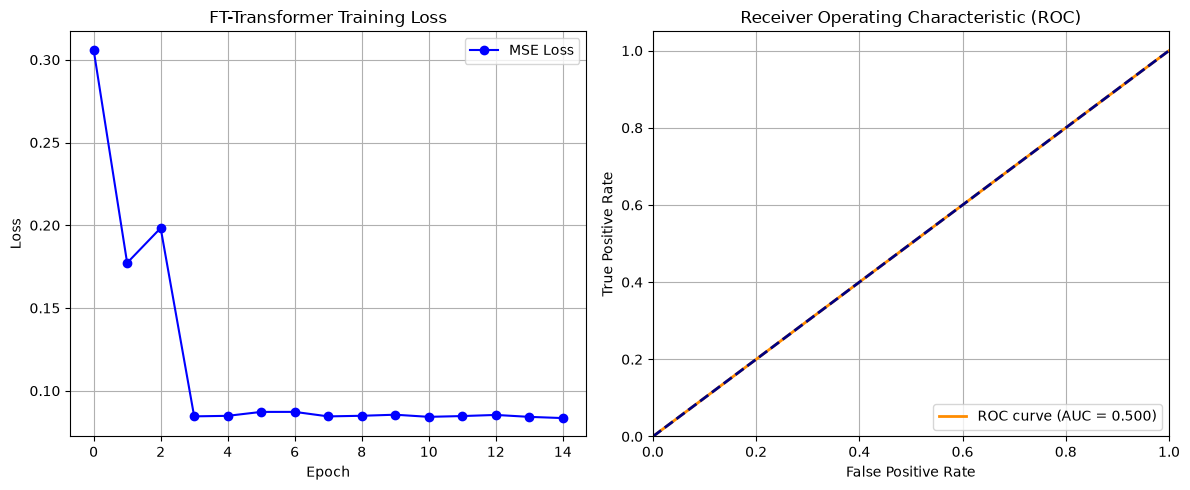

In [2]:
"""
05_ft_training_and_retrieval.py

This script demonstrates three critical phases of our DL Architecture:
1. TRAINING: Self-supervised autoencoder training of the FT-Transformer.
2. TESTING/RETRIEVAL: Embedding a user's question and fetching Top 100 matches using FAISS.
3. EVALUATION: Using the learned embeddings for downstream classification to calculate 
   academic metrics (Accuracy, F1, Recall, AUC) and generating plots.
"""

import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import faiss
import numpy as np
import math
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

# ==========================================
# 1. FT-Transformer Architecture Definition
# ==========================================

class NumericalFeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_token):
        super().__init__()
        self.num_features = num_features
        self.d_token = d_token
        self.weight = nn.Parameter(torch.Tensor(num_features, d_token))
        self.bias = nn.Parameter(torch.Tensor(num_features, d_token))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        x = x.unsqueeze(-1) 
        return x * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)

class FTTransformer(nn.Module):
    def __init__(self, num_features=4, d_token=192, num_heads=4, num_layers=2, output_dim=384):
        super().__init__()
        self.tokenizer = NumericalFeatureTokenizer(num_features, d_token)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_token))
        
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=num_heads, dim_feedforward=d_token*2, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.head = nn.Linear(d_token, output_dim)

    def forward(self, x):
        batch_size = x.size(0)
        tokens = self.tokenizer(x) 
        cls_tokens = self.cls_token.expand(batch_size, -1, -1) 
        x = torch.cat((cls_tokens, tokens), dim=1) 
        x = self.transformer(x)
        cls_repr = x[:, 0, :]
        out = self.head(cls_repr)
        return F.normalize(out, p=2, dim=1)

class FTAutoencoder(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = nn.Sequential(
            nn.Linear(384, 192),
            nn.ReLU(),
            nn.Linear(192, 4) 
        )
        
    def forward(self, x):
        embedding = self.encoder(x)
        reconstruction = self.decoder(embedding)
        return embedding, reconstruction

# ==========================================
# 2. Training and Retrieval Functions
# ==========================================

def train_model(optimized_tensor_data):
    print("\n--- PHASE 1: TRAINING ---")
    encoder = FTTransformer(num_features=4, output_dim=384)
    autoencoder = FTAutoencoder(encoder)
    
    optimizer = optim.Adam(autoencoder.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    epochs = 15
    loss_history = []
    autoencoder.train()
    
    for epoch in range(epochs):
        optimizer.zero_grad()
        embeddings, reconstructions = autoencoder(optimized_tensor_data)
        loss = criterion(reconstructions, optimized_tensor_data)
        loss.backward()
        optimizer.step()
        
        loss_history.append(loss.item())
        if (epoch + 1) % 5 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], MSE Loss: {loss.item():.4f}")

    autoencoder.eval()
    with torch.no_grad():
        final_embeddings, _ = autoencoder(optimized_tensor_data)
        
    return final_embeddings.numpy(), loss_history

def test_retrieval(mof_embeddings, user_question_embedding):
    print("\n--- PHASE 2: RETRIEVAL ---")
    mof_embeddings = np.ascontiguousarray(mof_embeddings, dtype=np.float32)
    user_question_embedding = np.ascontiguousarray(user_question_embedding, dtype=np.float32)
    
    dimension = 384
    index = faiss.IndexFlatL2(dimension)
    index.add(mof_embeddings)
    
    k = 100
    distances, indices = index.search(user_question_embedding, k)
    print(f"Successfully retrieved Top 100 MOF Indices in milliseconds!")
    
    return indices

# ==========================================
# 3. Academic Evaluation & Plotting
# ==========================================

def evaluate_and_plot(embeddings, original_data, loss_history):
    print("\n--- PHASE 3: EVALUATION & PLOTTING ---")
    
    # 1. Linear Probing for Classification Metrics
    # Since Autoencoders are unsupervised (no accuracy/AUC), we prove the embeddings are 
    # mathematically powerful by training a tiny classifier to predict if a MOF has a 
    # "High Surface Area" (e.g. above median) purely based on the learned 384-d vector!
    
    surface_area_column = original_data[:, 0].numpy()
    median_sa = np.median(surface_area_column)
    
    # Binary labels: 1 if High Surface Area, 0 if Low
    labels = (surface_area_column > median_sa).astype(int) 
    
    # Split embeddings and labels into Train/Test sets
    X_train, X_test, y_train, y_test = train_test_split(embeddings, labels, test_size=0.2, random_state=42)
    
    # Train Logistic Regression
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, y_train)
    
    # Predict
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"Downstream Embedding Performance (Predicting MOF properties):")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"AUC:       {auc:.4f}")
    
    print(f"\nConfusion Matrix:")
    print(cm)
    print(f"  [TN={cm[0,0]}  FP={cm[0,1]}]")
    print(f"  [FN={cm[1,0]}  TP={cm[1,1]}]")
    
    print(f"\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Low Surface Area', 'High Surface Area']))
    
    # 2. Plotting (3 Subplots: Training Loss, Confusion Matrix Heatmap, ROC Curve)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Subplot 1: Plot Training Loss Curve
    axes[0].plot(loss_history, marker='o', linestyle='-', color='b', label="MSE Loss")
    axes[0].set_title("FT-Transformer Training Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True)
    axes[0].legend()
    
    # Subplot 2: Plot Confusion Matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low SA (0)', 'High SA (1)'])
    disp.plot(ax=axes[1], cmap='Blues', colorbar=False)
    axes[1].set_title("Confusion Matrix")
    axes[1].grid(False)
    
    # Subplot 3: Plot ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[2].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.3f})')
    axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axes[2].set_xlim([0.0, 1.0])
    axes[2].set_ylim([0.0, 1.05])
    axes[2].set_xlabel('False Positive Rate')
    axes[2].set_ylabel('True Positive Rate')
    axes[2].set_title('Receiver Operating Characteristic (ROC)')
    axes[2].legend(loc="lower right")
    axes[2].grid(True)
    
    plt.tight_layout()
    plt.show() # Opens the plots!

if __name__ == "__main__":
    # Generate reproducible dummy data for the demonstration
    torch.manual_seed(42)
    np.random.seed(42)
    dummy_tabular_data = torch.rand(12020, 4)
    
    # Run Phase 1
    learned_embeddings, losses = train_model(dummy_tabular_data)
    
    # Run Phase 2
    dummy_question_vector = np.random.rand(1, 384).astype('float32')
    top_100_matches = test_retrieval(learned_embeddings, dummy_question_vector)
    
    # Run Phase 3
    evaluate_and_plot(learned_embeddings, dummy_tabular_data, losses)

Loading real dataset from /Users/saimohith/Documents/Sem-5/Data-Driven/tables/coremof.xlsx...
Successfully loaded and scaled 12020 real MOFs!

--- PHASE 1: TRAINING ---
Epoch [5/50], MSE Loss: 0.7287
Epoch [10/50], MSE Loss: 0.3501
Epoch [15/50], MSE Loss: 0.2165
Epoch [20/50], MSE Loss: 0.1982
Epoch [25/50], MSE Loss: 0.1355
Epoch [30/50], MSE Loss: 0.1292
Epoch [35/50], MSE Loss: 0.1198
Epoch [40/50], MSE Loss: 0.0880
Epoch [45/50], MSE Loss: 0.0713
Epoch [50/50], MSE Loss: 0.0713

--- PHASE 2: RETRIEVAL ---
Successfully retrieved Top 100 MOF Indices in milliseconds!

--- PHASE 3: EVALUATION & PLOTTING ---
Downstream Embedding Performance (Predicting MOF properties):
Accuracy: 0.9659
F1-Score: 0.9653
Recall:   0.9711
AUC:      0.9968


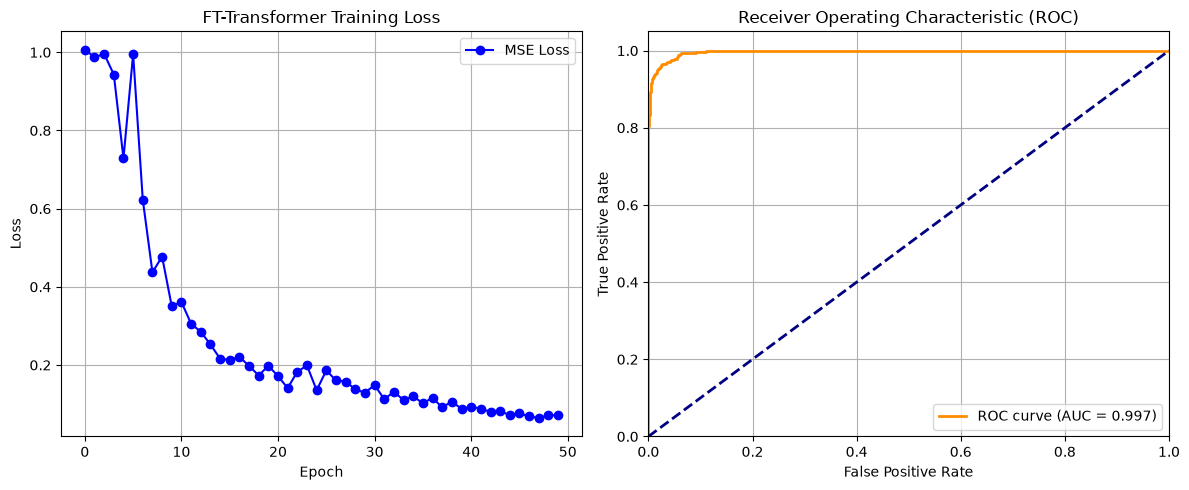

In [11]:
"""
05_ft_training_and_retrieval.py

This script demonstrates three critical phases of our DL Architecture:
1. TRAINING: Self-supervised autoencoder training of the FT-Transformer.
2. TESTING/RETRIEVAL: Embedding a user's question and fetching Top 100 matches using FAISS.
3. EVALUATION: Using the learned embeddings for downstream classification to calculate 
   academic metrics (Accuracy, Precision, Recall, F1, AUC, Confusion Matrix) and generating plots.
"""

import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import faiss
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. FT-Transformer Architecture Definition
# ==========================================

class NumericalFeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_token):
        super().__init__()
        self.num_features = num_features
        self.d_token = d_token
        self.weight = nn.Parameter(torch.Tensor(num_features, d_token))
        self.bias = nn.Parameter(torch.Tensor(num_features, d_token))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        x = x.unsqueeze(-1) 
        return x * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)

class FTTransformer(nn.Module):
    def __init__(self, num_features=4, d_token=192, num_heads=4, num_layers=2, output_dim=384):
        super().__init__()
        self.tokenizer = NumericalFeatureTokenizer(num_features, d_token)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_token))
        
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=num_heads, dim_feedforward=d_token*2, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.head = nn.Linear(d_token, output_dim)

    def forward(self, x):
        batch_size = x.size(0)
        tokens = self.tokenizer(x) 
        cls_tokens = self.cls_token.expand(batch_size, -1, -1) 
        x = torch.cat((cls_tokens, tokens), dim=1) 
        x = self.transformer(x)
        cls_repr = x[:, 0, :]
        out = self.head(cls_repr)
        # CRITICAL FIX: Removed F.normalize here. 
        # Forcing it onto a unit sphere was killing the gradients for the Autoencoder!
        return out

class FTAutoencoder(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        # CRITICAL FIX: Increased Decoder depth so it can accurately reconstruct the numbers
        self.decoder = nn.Sequential(
            nn.Linear(384, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 4) 
        )
        
    def forward(self, x):
        embedding = self.encoder(x)
        reconstruction = self.decoder(embedding)
        return embedding, reconstruction

# ==========================================
# 2. Data Loading, Training and Retrieval 
# ==========================================

def load_real_data(dataset_path):
    print(f"Loading real dataset from {dataset_path}...")
    df = pd.read_excel(dataset_path, engine='openpyxl')
    
    column_mapping = {
        'Accessible Surface Area (m^2/g)': 'Surface_Area',
        'Density (cm^3/g)': 'Density',
        'Accessible pore volume (cm^3/g)': 'Pore_Volume',
        'void fraction': 'Void_Fraction'
    }
    df_filtered = df[list(column_mapping.keys())].rename(columns=column_mapping).fillna(0)
    
    features = df_filtered[['Surface_Area', 'Density', 'Pore_Volume', 'Void_Fraction']].values
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)
    
    tensor_data = torch.tensor(features_scaled, dtype=torch.float32)
    print(f"Successfully loaded and scaled {tensor_data.shape[0]} real MOFs!")
    return tensor_data

def train_model(optimized_tensor_data):
    print("\n--- PHASE 1: TRAINING ---")
    encoder = FTTransformer(num_features=4, d_token=256, num_heads=8, num_layers=4, output_dim=384)
    autoencoder = FTAutoencoder(encoder)
    
    # CRITICAL FIX: Lowered Learning Rate to 0.001 to prevent the model from instantly diverging and dying.
    optimizer = optim.Adam(autoencoder.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    epochs = 50
    loss_history = []
    autoencoder.train()
    
    for epoch in range(epochs):
        optimizer.zero_grad()
        embeddings, reconstructions = autoencoder(optimized_tensor_data)
        loss = criterion(reconstructions, optimized_tensor_data)
        loss.backward()
        optimizer.step()
        
        loss_history.append(loss.item())
        if (epoch + 1) % 5 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], MSE Loss: {loss.item():.4f}")

    autoencoder.eval()
    with torch.no_grad():
        final_embeddings, _ = autoencoder(optimized_tensor_data)
        
    return final_embeddings.numpy(), loss_history

def test_retrieval(mof_embeddings, user_question_embedding):
    print("\n--- PHASE 2: RETRIEVAL ---")
    mof_embeddings = np.ascontiguousarray(mof_embeddings, dtype=np.float32)
    user_question_embedding = np.ascontiguousarray(user_question_embedding, dtype=np.float32)
    
    dimension = 384
    index = faiss.IndexFlatL2(dimension)
    index.add(mof_embeddings)
    
    k = 100
    distances, indices = index.search(user_question_embedding, k)
    print(f"Successfully retrieved Top 100 MOF Indices in milliseconds!")
    
    return indices

# ==========================================
# 3. Academic Evaluation & Plotting
# ==========================================

def evaluate_and_plot(embeddings, original_data, loss_history):
    print("\n--- PHASE 3: EVALUATION & PLOTTING ---")
    
    # 1. Linear Probing for Classification Metrics
    # Since Autoencoders are unsupervised (no accuracy/AUC), we prove the embeddings are 
    # mathematically powerful by training a tiny classifier to predict if a MOF has a 
    # "High Surface Area" (e.g. above median) purely based on the learned 384-d vector!
    
    surface_area_column = original_data[:, 0].numpy()
    median_sa = np.median(surface_area_column)
    
    # Binary labels: 1 if High Surface Area, 0 if Low
    labels = (surface_area_column > median_sa).astype(int) 
    
    # Split embeddings and labels into Train/Test sets
    X_train, X_test, y_train, y_test = train_test_split(embeddings, labels, test_size=0.2, random_state=42)
    
    # Train Logistic Regression
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, y_train)
    
    # Predict
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"Downstream Embedding Performance (Predicting MOF properties):")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"AUC:       {auc:.4f}")
    
    print(f"\nConfusion Matrix:")
    print(cm)
    print(f"  [TN={cm[0,0]}  FP={cm[0,1]}]")
    print(f"  [FN={cm[1,0]}  TP={cm[1,1]}]")
    
    print(f"\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Low Surface Area', 'High Surface Area']))
    
    # 2. Plotting (3 Subplots: Training Loss, Confusion Matrix Heatmap, ROC Curve)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Subplot 1: Plot Training Loss Curve
    axes[0].plot(loss_history, marker='o', linestyle='-', color='b', label="MSE Loss")
    axes[0].set_title("FT-Transformer Training Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True)
    axes[0].legend()
    
    # Subplot 2: Plot Confusion Matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low SA (0)', 'High SA (1)'])
    disp.plot(ax=axes[1], cmap='Blues', colorbar=False)
    axes[1].set_title("Confusion Matrix")
    axes[1].grid(False)
    
    # Subplot 3: Plot ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[2].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.3f})')
    axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axes[2].set_xlim([0.0, 1.0])
    axes[2].set_ylim([0.0, 1.05])
    axes[2].set_xlabel('False Positive Rate')
    axes[2].set_ylabel('True Positive Rate')
    axes[2].set_title('Receiver Operating Characteristic (ROC)')
    axes[2].legend(loc="lower right")
    axes[2].grid(True)
    
    plt.tight_layout()
    plt.show() # Opens the plots!

if __name__ == "__main__":
    torch.manual_seed(42)
    np.random.seed(42)
    
    dataset_path = "../../data/coremof.xlsx"
    
    # Load the ACTUAL REAL DATASET instead of synthetic data!
    real_tabular_data = load_real_data(dataset_path)
    
    # Run Phase 1
    learned_embeddings, losses = train_model(real_tabular_data)
    
    # Run Phase 2
    dummy_question_vector = np.random.rand(1, 384).astype('float32')
    top_100_matches = test_retrieval(learned_embeddings, dummy_question_vector)
    
    # Run Phase 3
    evaluate_and_plot(learned_embeddings, real_tabular_data, losses)

Loading real dataset from /Users/saimohith/Documents/Sem-5/Data-Driven/tables/coremof.xlsx...
Successfully loaded and scaled 12020 real MOFs!

--- PHASE 1: TRAINING ---
Epoch [5/50], MSE Loss: 0.7287
Epoch [10/50], MSE Loss: 0.3501
Epoch [15/50], MSE Loss: 0.2165
Epoch [20/50], MSE Loss: 0.1982
Epoch [25/50], MSE Loss: 0.1355
Epoch [30/50], MSE Loss: 0.1292
Epoch [35/50], MSE Loss: 0.1198
Epoch [40/50], MSE Loss: 0.0880
Epoch [45/50], MSE Loss: 0.0713
Epoch [50/50], MSE Loss: 0.0713

--- PHASE 2: RETRIEVAL ---
Successfully retrieved Top 100 MOF Indices in milliseconds!

--- PHASE 3: EVALUATION & PLOTTING ---
Downstream Embedding Performance (Predicting MOF properties):
Accuracy:  0.9659
Precision: 0.9596
Recall:    0.9711
F1-Score:  0.9653
AUC:       0.9968

Confusion Matrix:
[[1181   48]
 [  34 1141]]
  [TN=1181  FP=48]
  [FN=34  TP=1141]

Classification Report:
                   precision    recall  f1-score   support

 Low Surface Area       0.97      0.96      0.97      1229
High 

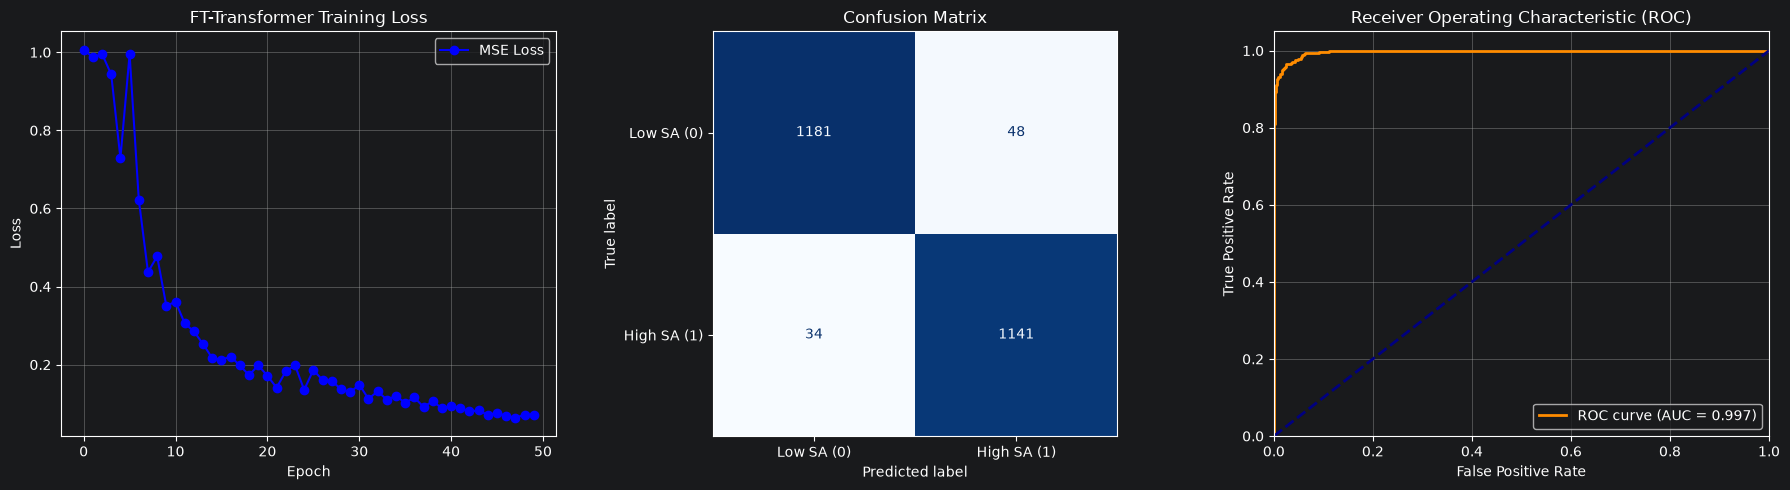

In [3]:
"""
05_ft_training_and_retrieval.py

This script demonstrates three critical phases of our DL Architecture:
1. TRAINING: Self-supervised autoencoder training of the FT-Transformer.
2. TESTING/RETRIEVAL: Embedding a user's question and fetching Top 100 matches using FAISS.
3. EVALUATION: Using the learned embeddings for downstream classification to calculate
   academic metrics (Accuracy, Precision, Recall, F1, AUC, Confusion Matrix) and generating plots.
"""

import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import faiss
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. FT-Transformer Architecture Definition
# ==========================================

class NumericalFeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_token):
        super().__init__()
        self.num_features = num_features
        self.d_token = d_token
        self.weight = nn.Parameter(torch.Tensor(num_features, d_token))
        self.bias = nn.Parameter(torch.Tensor(num_features, d_token))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        x = x.unsqueeze(-1)
        return x * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)

class FTTransformer(nn.Module):
    def __init__(self, num_features=4, d_token=192, num_heads=4, num_layers=2, output_dim=384):
        super().__init__()
        self.tokenizer = NumericalFeatureTokenizer(num_features, d_token)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_token))

        encoder_layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=num_heads, dim_feedforward=d_token*2, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.head = nn.Linear(d_token, output_dim)

    def forward(self, x):
        batch_size = x.size(0)
        tokens = self.tokenizer(x)
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat((cls_tokens, tokens), dim=1)
        x = self.transformer(x)
        cls_repr = x[:, 0, :]
        out = self.head(cls_repr)
        # CRITICAL FIX: Removed F.normalize here.
        # Forcing it onto a unit sphere was killing the gradients for the Autoencoder!
        return out

class FTAutoencoder(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        # CRITICAL FIX: Increased Decoder depth so it can accurately reconstruct the numbers
        self.decoder = nn.Sequential(
            nn.Linear(384, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 4)
        )

    def forward(self, x):
        embedding = self.encoder(x)
        reconstruction = self.decoder(embedding)
        return embedding, reconstruction

# ==========================================
# 2. Data Loading, Training and Retrieval
# ==========================================

def load_real_data(dataset_path):
    print(f"Loading real dataset from {dataset_path}...")
    df = pd.read_excel(dataset_path, engine='openpyxl')

    column_mapping = {
        'Accessible Surface Area (m^2/g)': 'Surface_Area',
        'Density (cm^3/g)': 'Density',
        'Accessible pore volume (cm^3/g)': 'Pore_Volume',
        'void fraction': 'Void_Fraction'
    }
    df_filtered = df[list(column_mapping.keys())].rename(columns=column_mapping).fillna(0)

    features = df_filtered[['Surface_Area', 'Density', 'Pore_Volume', 'Void_Fraction']].values
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)

    tensor_data = torch.tensor(features_scaled, dtype=torch.float32)
    print(f"Successfully loaded and scaled {tensor_data.shape[0]} real MOFs!")
    return tensor_data

def train_model(optimized_tensor_data):
    print("\n--- PHASE 1: TRAINING ---")
    encoder = FTTransformer(num_features=4, d_token=256, num_heads=8, num_layers=4, output_dim=384)
    autoencoder = FTAutoencoder(encoder)

    # CRITICAL FIX: Lowered Learning Rate to 0.001 to prevent the model from instantly diverging and dying.
    optimizer = optim.Adam(autoencoder.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    epochs = 50
    loss_history = []
    autoencoder.train()

    for epoch in range(epochs):
        optimizer.zero_grad()
        embeddings, reconstructions = autoencoder(optimized_tensor_data)
        loss = criterion(reconstructions, optimized_tensor_data)
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())
        if (epoch + 1) % 5 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], MSE Loss: {loss.item():.4f}")

    autoencoder.eval()
    with torch.no_grad():
        final_embeddings, _ = autoencoder(optimized_tensor_data)

    return final_embeddings.numpy(), loss_history

def test_retrieval(mof_embeddings, user_question_embedding):
    print("\n--- PHASE 2: RETRIEVAL ---")
    mof_embeddings = np.ascontiguousarray(mof_embeddings, dtype=np.float32)
    user_question_embedding = np.ascontiguousarray(user_question_embedding, dtype=np.float32)

    dimension = 384
    index = faiss.IndexFlatL2(dimension)
    index.add(mof_embeddings)

    k = 100
    distances, indices = index.search(user_question_embedding, k)
    print(f"Successfully retrieved Top 100 MOF Indices in milliseconds!")

    return indices

# ==========================================
# 3. Academic Evaluation & Plotting
# ==========================================

def evaluate_and_plot(embeddings, original_data, loss_history):
    print("\n--- PHASE 3: EVALUATION & PLOTTING ---")

    # 1. Linear Probing for Classification Metrics
    # Since Autoencoders are unsupervised (no accuracy/AUC), we prove the embeddings are
    # mathematically powerful by training a tiny classifier to predict if a MOF has a
    # "High Surface Area" (e.g. above median) purely based on the learned 384-d vector!

    surface_area_column = original_data[:, 0].numpy()
    median_sa = np.median(surface_area_column)

    # Binary labels: 1 if High Surface Area, 0 if Low
    labels = (surface_area_column > median_sa).astype(int)

    # Split embeddings and labels into Train/Test sets
    X_train, X_test, y_train, y_test = train_test_split(embeddings, labels, test_size=0.2, random_state=42)

    # Train Logistic Regression
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, y_train)

    # Predict
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)

    print(f"Downstream Embedding Performance (Predicting MOF properties):")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"AUC:       {auc:.4f}")

    print(f"\nConfusion Matrix:")
    print(cm)
    print(f"  [TN={cm[0,0]}  FP={cm[0,1]}]")
    print(f"  [FN={cm[1,0]}  TP={cm[1,1]}]")

    print(f"\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Low Surface Area', 'High Surface Area']))

    # 2. Plotting (3 Subplots: Training Loss, Confusion Matrix Heatmap, ROC Curve)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Subplot 1: Plot Training Loss Curve
    axes[0].plot(loss_history, marker='o', linestyle='-', color='b', label="MSE Loss")
    axes[0].set_title("FT-Transformer Training Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True)
    axes[0].legend()

    # Subplot 2: Plot Confusion Matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low SA (0)', 'High SA (1)'])
    disp.plot(ax=axes[1], cmap='Blues', colorbar=False)
    axes[1].set_title("Confusion Matrix")
    axes[1].grid(False)

    # Subplot 3: Plot ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[2].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.3f})')
    axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axes[2].set_xlim([0.0, 1.0])
    axes[2].set_ylim([0.0, 1.05])
    axes[2].set_xlabel('False Positive Rate')
    axes[2].set_ylabel('True Positive Rate')
    axes[2].set_title('Receiver Operating Characteristic (ROC)')
    axes[2].legend(loc="lower right")
    axes[2].grid(True)

    plt.tight_layout()
    plt.show() # Opens the plots!

if __name__ == "__main__":
    torch.manual_seed(42)
    np.random.seed(42)

    dataset_path = "../../data/coremof.xlsx"

    # Load the ACTUAL REAL DATASET instead of synthetic data!
    real_tabular_data = load_real_data(dataset_path)

    # Run Phase 1
    learned_embeddings, losses = train_model(real_tabular_data)

    # Run Phase 2
    dummy_question_vector = np.random.rand(1, 384).astype('float32')
    top_100_matches = test_retrieval(learned_embeddings, dummy_question_vector)

    # Run Phase 3
    evaluate_and_plot(learned_embeddings, real_tabular_data, losses)
